# Used-Vehicle Price Estimation in Sri Lanka
### 01 / Data Cleaning, Quality Assessment & Exploratory Analysis

**MSc Machine Learning · Final Assignment**  
**Analysis unit:** advertisement listing · **Prediction target:** advertised asking price in LKR 

The study examines scraped Sri Lankan vehicle advertisements. This notebook profiles the raw listings, applies documented data-quality controls, then presents exploratory analysis of the cleaned dataset before exporting modelling inputs. Seller-advertised prices are not verified transaction values.

## 1. Dataset ingestion and source structure

The original Ikman dataset is loaded without modifying the source file. Subsequent cleaning uses a separate DataFrame so that transformations remain auditable.

In [1]:
from pathlib import Path
from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.6), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 55)


In [2]:
# Resolve the project directory in Colab, JupyterLab or a local Python environment.
from pathlib import Path
import os

PROJECT_NAME = 'Sri_Lanka_Vehicle_Price_Jupyter_Notebooks'
DRIVE_ROOT = Path('/content/drive/MyDrive')
if Path('/content').exists() and not DRIVE_ROOT.exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass

locations = [Path.cwd(), DRIVE_ROOT / PROJECT_NAME,
             DRIVE_ROOT / 'Sri_Lanka_Vehicle_Price_Final_Assignment',
             Path('/content'), Path('/mnt/data')]
PROJECT_DIR = next((p for p in locations if (p / 'ikman-scrapes.csv').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('ikman-scrapes.csv was not found in the notebook project directory.')
RAW_CSV = PROJECT_DIR / 'ikman-scrapes.csv'
OUTPUT_DIR = PROJECT_DIR / 'vehicle_ml_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_CSV = OUTPUT_DIR / 'cleaned_vehicle_data.csv'
AUDIT_JSON = OUTPUT_DIR / 'cleaning_report.json'
print('Dataset:', RAW_CSV)
print('Outputs:', OUTPUT_DIR)

Dataset: /mnt/data/ikman-scrapes.csv
Outputs: /mnt/data/vehicle_ml_outputs


In [3]:
raw = pd.read_csv(RAW_CSV, low_memory=False)
expected_columns = [
    "Brand", "Model", "Edition", "Year of Manufacture", "Transmission",
    "Fuel Type", "Body Type", "Engine Capacity (cc)", "Mileage (km)",
    "Price Rs.", "Negotiable"
]
missing_columns = sorted(set(expected_columns) - set(raw.columns))
assert not missing_columns, f"Expected columns missing: {missing_columns}"

dataset_overview = pd.DataFrame({
    "Measure": ["Source records", "Original attributes", "Numeric-like columns", "Categorical columns"],
    "Value": [len(raw), len(expected_columns), 4, 7],
})
display(dataset_overview.style.format({"Value": "{:,.0f}"}).hide(axis='index'))
display(raw.head(6))

Measure,Value
Source records,"10,388"
Original attributes,11
Numeric-like columns,4
Categorical columns,7


,Brand,Model,Edition,Year of Manufacture,Transmission,Fuel Type,Body Type,Engine Capacity (cc),Mileage (km),Price Rs.,Negotiable
0,Audi,A3,NaN,2023,Automatic,Petrol,Saloon,"1,500 cc",0 km,"Rs 20,500,000",Yes
1,Audi,A3,SPORT BACK S LINE,2023,Automatic,Petrol,Hatchback,"1,000 cc","11,000 km","Rs 18,500,000",Yes
2,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
3,Ford,Laser,GL,1988,Manual,Petrol,Saloon,"1,500 cc","250,000 km","Rs 1,000,000",Yes
4,Honda,Clarity,NaN,2005,Manual,Petrol,Coupé/Sports,"1,000 cc","20,000 km","Rs 1,000,000",Yes
5,Mitsubishi,Lancer,Lancer Wagon 1200,1983,Manual,Petrol,Station wagon,"1,200 cc","67,340 km","Rs 1,000,000",No


## 2. Initial data-quality assessment

This preliminary audit identifies missing values, field types, and category cardinality **before cleaning**. It provides the basis for defining quality-control rules; full exploratory visualizations are consolidated in Section 6.

In [4]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": raw.isna().mean().mul(100),
    "unique": raw.nunique(dropna=True),
})
display(profile.style.format({"missing_%": "{:.1f}%"}))

source_checks = pd.DataFrame({
    "Diagnostic": ["Original observations", "Null cells", "Identical raw rows"],
    "Count": [len(raw), int(raw.isna().sum().sum()), int(raw.duplicated().sum())]
})
display(source_checks.style.format({"Count": "{:,.0f}"}).hide(axis="index"))

,dtype,missing,missing_%,unique
Brand,object,0,0.0%,57
Model,object,0,0.0%,473
Edition,object,1559,15.0%,3956
Year of Manufacture,int64,0,0.0%,65
Transmission,object,0,0.0%,4
Fuel Type,object,0,0.0%,6
Body Type,object,910,8.8%,7
Engine Capacity (cc),object,0,0.0%,276
Mileage (km),object,0,0.0%,1805
Price Rs.,object,0,0.0%,1588


Diagnostic,Count
Original observations,"10,388"
Null cells,"2,469"
Identical raw rows,"1,814"


## 3. Variable normalization

Categorical text is standardized for spacing and capitalization, and currency or measurement strings are converted to numeric values. The normalized pre-cleaning snapshot is preserved for the EDA comparison. No learned imputation or encoding is fitted here.

In [5]:
column_names = {
    "Year of Manufacture": "ManufactureYear", "Fuel Type": "FuelType",
    "Body Type": "BodyType", "Engine Capacity (cc)": "EngineCC",
    "Mileage (km)": "MileageKM", "Price Rs.": "PriceLKR",
}
CAT = ["Brand", "Model", "Edition", "Transmission", "FuelType", "BodyType", "Negotiable"]
NUM = ["ManufactureYear", "EngineCC", "MileageKM"]
FEATURES = CAT + NUM
TARGET = "PriceLKR"

def parse_listing_number(s: pd.Series) -> pd.Series:
    """Remove units/commas/currency from values such as 'Rs 12,500,000'."""
    cleaned = s.astype("string").str.replace(r"[^\d.]", "", regex=True)
    return pd.to_numeric(cleaned.replace("", pd.NA), errors="coerce").astype(float)

def normalize_listing_text(s: pd.Series) -> pd.Series:
    """Harmonize whitespace/case, but avoid guessing brand/model synonyms."""
    s = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    tokens = {"", "nan", "none", "null", "n/a", "na", "unknown", "not available", "-"}
    return s.mask(s.str.casefold().isin(tokens)).str.title()

df = raw[expected_columns].rename(columns=column_names).copy()
for col in CAT:
    df[col] = normalize_listing_text(df[col]).fillna("Unknown")
for col in NUM + [TARGET]:
    df[col] = parse_listing_number(df[col])

display(df.sample(min(8, len(df)), random_state=SEED))


# Preserve normalized observations before any exclusion or validity rule.
normalized_raw = df.copy()

,Brand,Model,Edition,ManufactureYear,Transmission,FuelType,BodyType,EngineCC,MileageKM,PriceLKR,Negotiable
8954,Toyota,Corolla,141 Gli,2011.0,Automatic,Petrol,Saloon,1600.0,200000.0,8400000.0,Yes
6495,Suzuki,Wagon R Stingray,Unknown,2015.0,Automatic,Hybrid,Hatchback,650.0,89000.0,5800000.0,Yes
4184,Toyota,Yaris Cross,Unknown,2025.0,Automatic,Hybrid,Suv / 4X4,1496.0,9669.0,21000000.0,No
7015,Daihatsu,Mira,Es L,2023.0,Automatic,Petrol,Hatchback,660.0,8000.0,6375000.0,Yes
5860,Suzuki,Celerio,Unknown,2015.0,Manual,Petrol,Hatchback,1000.0,49800.0,4650000.0,Yes
7467,Suzuki,Alto,Hybrid S Grade,2023.0,Automatic,Hybrid,Station Wagon,660.0,8600.0,6900000.0,Yes
4245,Honda,Vezel,Z-Play,2025.0,Automatic,Hybrid,Hatchback,1500.0,0.0,21700000.0,No
1692,Honda,Vezel,Honda Vezel Rs 2018,2018.0,Automatic,Hybrid,Suv / 4X4,1500.0,100000.0,13200000.0,Yes


## 4. Data cleaning and quality-control policy

The following explicit rules are applied to standardized records. Study-specific thresholds should be treated as documented assumptions rather than verified market boundaries.

| Issue | Treatment | Rationale |
|---|---|---|
| Duplicate specification-and-price records | Retain first | Reduce identical scrape observations |
| Missing/nonpositive asking price | Exclude | Invalid supervised target |
| Price greater than LKR 1 billion | Exclude and audit | Extreme suspected entry error (study-specific threshold) |
| Manufacturing year outside 1950–execution year | Exclude | Inconsistent temporal measurement |
| Zero odometer for a vehicle built in 2022 or earlier | Set mileage missing | Likely placeholder, not verified zero |
| Mileage outside 0–800,000 km | Set missing | Conservative plausibility threshold |
| Engine displacement outside 100–8,000 cc or electric vehicle | Set missing | Inconsistent or non-applicable field |
| Unusually low recent-vehicle prices | Flag only | May be a deposit listing; ambiguous without inspection |

No feature-imputation or categorical-encoding statistics are learned from the full dataset. Those transformations are fitted on training partitions in Notebook 02.

In [6]:
audit = {"source": RAW_CSV.name, "raw_rows": int(len(raw)), "rules": {}, "flags": {},
         "assumptions": ["Asking prices, not confirmed sales", "Unknown scrape date / advertisement ID"]}

is_duplicate = df.duplicated(keep="first")
audit["rules"]["exact_duplicates_removed"] = int(is_duplicate.sum())
df = df.loc[~is_duplicate].copy()

bad_label = df[TARGET].isna() | (df[TARGET] <= 0)
audit["rules"]["missing_or_nonpositive_price_removed"] = int(bad_label.sum())
df = df.loc[~bad_label].copy()

price_over_one_billion = df[TARGET] > 1_000_000_000
audit["flags"]["price_over_1b_examples"] = df.loc[
    price_over_one_billion, ["Brand", "Model", "ManufactureYear", "PriceLKR"]
].head(12).to_dict("records")
audit["rules"]["price_over_1b_removed"] = int(price_over_one_billion.sum())
df = df.loc[~price_over_one_billion].copy()

invalid_year = df.ManufactureYear.isna() | df.ManufactureYear.lt(1950) | df.ManufactureYear.gt(datetime.now().year)
audit["rules"]["invalid_year_removed"] = int(invalid_year.sum())
df = df.loc[~invalid_year].copy()
df["ManufactureYear"] = df["ManufactureYear"].astype(int)

zero_older = df.ManufactureYear.le(2022) & df.MileageKM.eq(0)
invalid_mileage = df.MileageKM.lt(0) | df.MileageKM.gt(800_000)
audit["rules"]["older_zero_mileage_set_missing"] = int(zero_older.sum())
audit["rules"]["extreme_mileage_set_missing"] = int(invalid_mileage.sum())
df.loc[zero_older | invalid_mileage, "MileageKM"] = np.nan

electric = df.FuelType.eq("Electric")
invalid_engine = df.EngineCC.lt(100) | df.EngineCC.gt(8_000)
audit["rules"]["electric_cc_set_missing"] = int((electric & df.EngineCC.notna()).sum())
audit["rules"]["implausible_cc_set_missing"] = int((~electric & invalid_engine).sum())
df.loc[electric | invalid_engine, "EngineCC"] = np.nan

low_recent = df.ManufactureYear.ge(2023) & df.PriceLKR.lt(2_000_000)
audit["rules"]["low_price_recent_flagged_not_removed"] = int(low_recent.sum())
audit["flags"]["low_price_recent_examples"] = df.loc[
    low_recent, ["Brand", "Model", "ManufactureYear", "PriceLKR"]
].head(15).to_dict("records")

cleaned = df[FEATURES + [TARGET]].reset_index(drop=True)
audit["clean_rows"] = int(len(cleaned))
audit["missing_after_cleaning"] = cleaned.isna().sum().astype(int).to_dict()
audit["price_quantiles_lkr"] = {
    str(q): float(v) for q, v in cleaned.PriceLKR.quantile([0, .01, .25, .5, .75, .99, 1]).items()
}
changes = pd.DataFrame([{"Decision": k.replace('_',' ').capitalize(), "Count": v} for k,v in audit["rules"].items()])
display(changes.style.bar(subset=["Count"], color="#b4d4e9"))
display(Markdown(f"**Retained {len(cleaned):,} of {len(raw):,} original observations.**"))

,Decision,Count
0,Exact duplicates removed,1833
1,Missing or nonpositive price removed,0
2,Price over 1b removed,1
3,Invalid year removed,0
4,Older zero mileage set missing,8
5,Extreme mileage set missing,13
6,Electric cc set missing,85
7,Implausible cc set missing,9
8,Low price recent flagged not removed,3


**Retained 8,554 of 10,388 original observations.**

## 5. Post-cleaning quality assessment

Review the remaining missing measurements and flagged low-price advertisements before conducting substantive EDA. Flagged records are retained where the available source data cannot verify an error.

In [7]:
missing = pd.DataFrame({
    "Missing records": cleaned.isna().sum(),
    "Missing (%)": cleaned.isna().mean().mul(100)
}).sort_values("Missing records", ascending=False)
display(missing.style.format({"Missing (%)": "{:.2f}%"}).background_gradient(
    subset=["Missing records"], cmap="Blues"
))

review_records = df.loc[low_recent, ["Brand", "Model", "ManufactureYear", "PriceLKR"]].head(12)
display(Markdown("**Flagged recent low-price listings (retained for transparency):**"))
display(review_records)

,Missing records,Missing (%)
EngineCC,94,1.10%
MileageKM,21,0.25%
Brand,0,0.00%
Edition,0,0.00%
Model,0,0.00%
Transmission,0,0.00%
FuelType,0,0.00%
Negotiable,0,0.00%
BodyType,0,0.00%
ManufactureYear,0,0.00%


**Flagged recent low-price listings (retained for transparency):**

,Brand,Model,ManufactureYear,PriceLKR
113,Toyota,Raize,2025,1430000.0
198,Honda,Vezel,2023,1780000.0
227,Honda,Vezel,2025,1880000.0


## 6. Exploratory Data Analysis (EDA)

All substantive visualizations are presented together **after cleaning**. The analysis examines vehicle-make composition, residual missingness, asking-price distributions, and relationships between price and numerical predictors. A pre-cleaning price comparison is retained to illustrate the effect of the outlier exclusion.

### 6.1 Vehicle-make representation and missingness

Brand frequencies and missing-value percentages are computed from the **cleaned** dataset, so the figures describe the records actually available for model development.

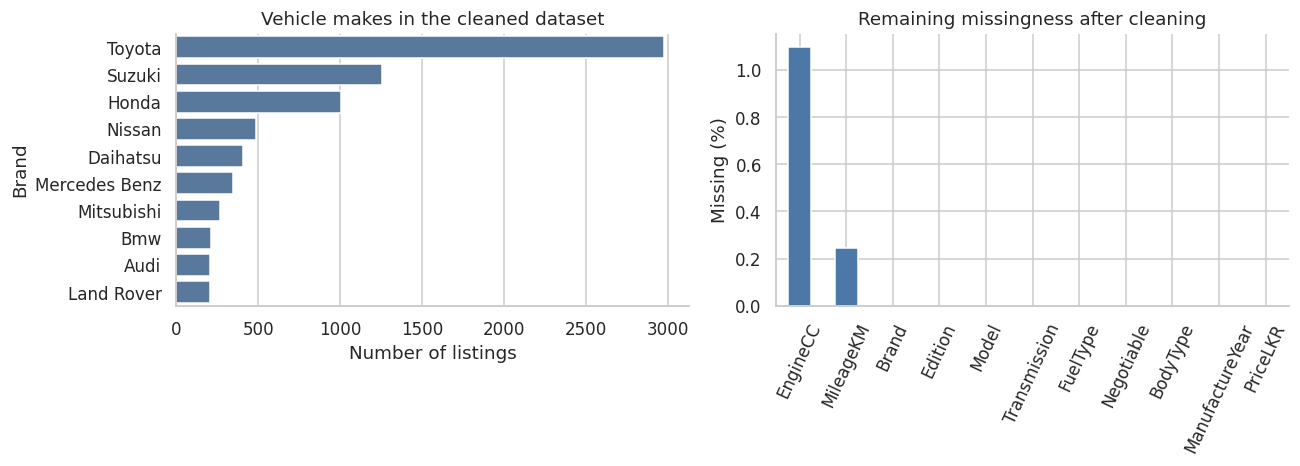

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
brand_counts = cleaned["Brand"].value_counts().head(10)
sns.barplot(x=brand_counts.values, y=brand_counts.index, ax=axes[0], color="#4C78A8")
axes[0].set(title="Vehicle makes in the cleaned dataset", xlabel="Number of listings", ylabel="Brand")

cleaned.isna().mean().mul(100).sort_values(ascending=False).plot(
    kind="bar", ax=axes[1], color="#4C78A8"
)
axes[1].set(title="Remaining missingness after cleaning", ylabel="Missing (%)", xlabel="")
axes[1].tick_params(axis="x", rotation=65)
plt.tight_layout()
plt.show()

*Figure 1.* Distribution of the most represented makes and remaining missing-value percentages in the cleaned dataset.

### 6.2 Asking-price distribution: before and after cleaning

The pre-cleaning price distribution provides context for the excluded extreme value. The cleaned distribution is also displayed with a 99th-percentile *visual limit*, and on a logarithmic scale. Plotting transformations do not alter the modelling target.

,Cleaned asking price (LKR)
count,"8,554"
mean,"17,399,015"
std,"22,062,618"
min,"295,000"
1%,"900,000"
5%,"2,300,000"
25%,"7,150,000"
50%,"10,690,000"
75%,"18,437,500"
95%,"57,500,000"


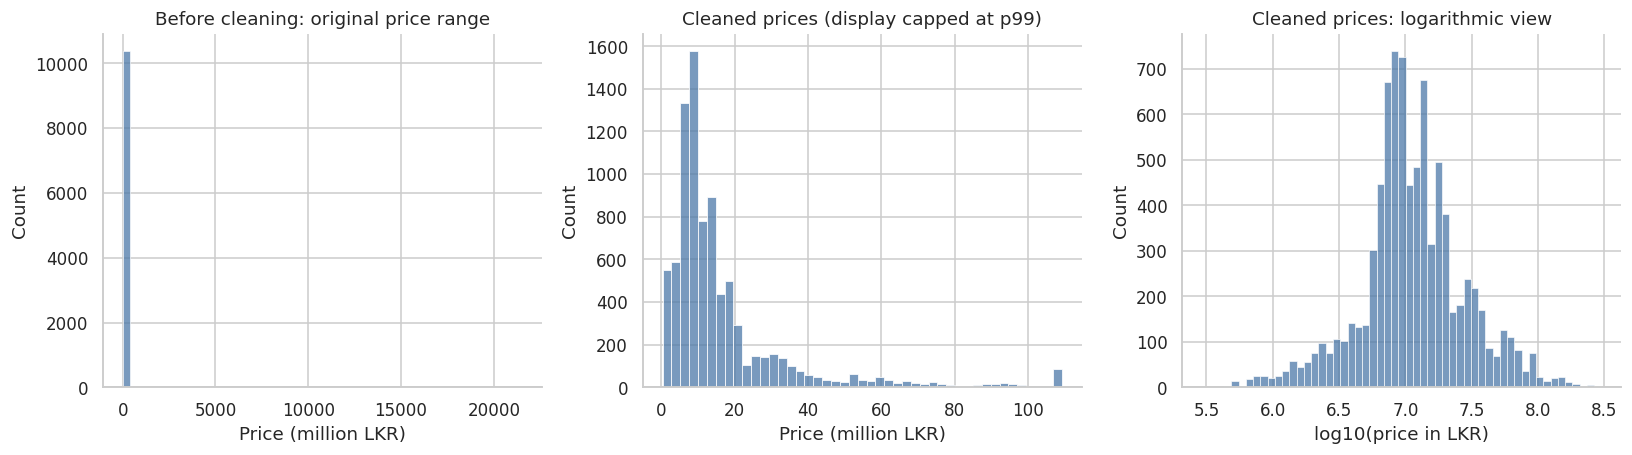

In [9]:
price_stats = cleaned["PriceLKR"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
display(price_stats.rename("Cleaned asking price (LKR)").to_frame().style.format(
    {"Cleaned asking price (LKR)": "{:,.0f}"}
))

raw_positive = normalized_raw.loc[normalized_raw["PriceLKR"] > 0, "PriceLKR"]
cleaned_positive = cleaned.loc[cleaned["PriceLKR"] > 0, "PriceLKR"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
sns.histplot(raw_positive / 1e6, bins=55, ax=axes[0], color="#4C78A8")
axes[0].set(title="Before cleaning: original price range", xlabel="Price (million LKR)")
sns.histplot((cleaned_positive / 1e6).clip(upper=cleaned_positive.quantile(.99) / 1e6),
             bins=45, ax=axes[1], color="#4C78A8")
axes[1].set(title="Cleaned prices (display capped at p99)", xlabel="Price (million LKR)")
sns.histplot(np.log10(cleaned_positive), bins=55, ax=axes[2], color="#4C78A8")
axes[2].set(title="Cleaned prices: logarithmic view", xlabel="log10(price in LKR)")
plt.tight_layout()
plt.show()

*Figure 2.* Price distribution before cleaning, among retained listings (capped at the 99th percentile for display), and on a logarithmic axis. Price values were not capped for model training.

### 6.3 Price relationships with manufacturing year and mileage

Scatter plots visualize broad associations rather than causal effects. To reduce overplotting, a reproducible random sample of up to 1,500 cleaned observations is displayed in each chart.

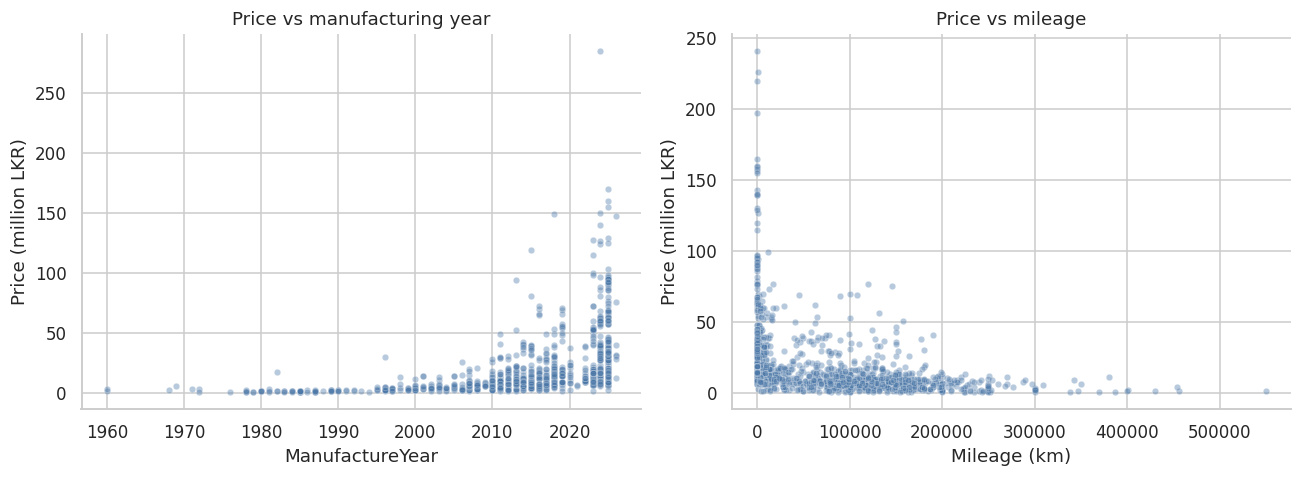

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_df = cleaned.copy()
plot_df["PriceMillions"] = plot_df["PriceLKR"] / 1e6

sns.scatterplot(data=plot_df.sample(min(1500, len(plot_df)), random_state=SEED),
                x="ManufactureYear", y="PriceMillions", alpha=.4, s=18,
                ax=axes[0], color="#4C78A8")
axes[0].set(title="Price vs manufacturing year", ylabel="Price (million LKR)")

mileage_df = plot_df.dropna(subset=["MileageKM"])
sns.scatterplot(data=mileage_df.sample(min(1500, len(mileage_df)), random_state=SEED),
                x="MileageKM", y="PriceMillions", alpha=.4, s=18,
                ax=axes[1], color="#4C78A8")
axes[1].set(title="Price vs mileage", xlabel="Mileage (km)", ylabel="Price (million LKR)")
plt.tight_layout()
plt.show()

*Figure 3.* Observed relationships between advertised price, manufacturing year, and mileage within the cleaned listing sample.

### 6.4 Main exploratory findings

**Dataset composition.** The most common vehicle makes account for a substantial proportion of listings; performance on less frequent makes may require separate examination.

**Price distribution.** Asking prices remain strongly right-skewed even after removing a demonstrably extreme entry; medians therefore better represent the typical listing than means.

**Feature associations.** Manufacturing year and mileage show broad, nonlinear associations with asking price, while substantial variation remains across other vehicle specifications. These observations motivate comparing nonlinear ensemble regressors, without implying causality.

## 7. Dataset validation and export

The final modelling dataset is checked for valid target values, duplicate rows, manufacturing years, and expected column order. Numerical missing values are intentionally retained for training-fold imputation in Notebook 02.

In [11]:
assert cleaned.PriceLKR.notna().all() and cleaned.PriceLKR.gt(0).all()
assert cleaned.ManufactureYear.between(1950, datetime.now().year).all()
assert cleaned.duplicated().sum() == 0
assert list(cleaned.columns) == FEATURES + [TARGET]
assert len(cleaned) > 1_000

cleaned.to_csv(CLEAN_CSV, index=False)
AUDIT_JSON.write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding='utf-8')

export_summary = pd.DataFrame({
    'Measure': ['Original records', 'Retained records', 'Excluded records', 'Retained proportion (%)'],
    'Result': [len(raw), len(cleaned), len(raw) - len(cleaned),
               100 * len(cleaned) / len(raw)],
})
display(export_summary.style.format({'Result': '{:,.1f}'}).hide(axis='index'))
display(Markdown(f'**Validated outputs:** `{CLEAN_CSV.name}` and `{AUDIT_JSON.name}`'))
display(cleaned.head(5))

Measure,Result
Original records,"10,388.0"
Retained records,"8,554.0"
Excluded records,"1,834.0"
Retained proportion (%),82.3


**Validated outputs:** `cleaned_vehicle_data.csv` and `cleaning_report.json`

,Brand,Model,Edition,Transmission,FuelType,BodyType,Negotiable,ManufactureYear,EngineCC,MileageKM,PriceLKR
0,Audi,A3,Unknown,Automatic,Petrol,Saloon,Yes,2023,1500.0,0.0,20500000.0
1,Audi,A3,Sport Back S Line,Automatic,Petrol,Hatchback,Yes,2023,1000.0,11000.0,18500000.0
2,Ford,Laser,Gl,Manual,Petrol,Saloon,Yes,1988,1500.0,250000.0,1000000.0
3,Honda,Clarity,Unknown,Manual,Petrol,Coupé/Sports,Yes,2005,1000.0,20000.0,1000000.0
4,Mitsubishi,Lancer,Lancer Wagon 1200,Manual,Petrol,Station Wagon,No,1983,1200.0,67340.0,1000000.0


### Preparation summary

The audit and validation results document all retained observations, exclusion decisions, and remaining missing numerical measurements. The original CSV remains unchanged; the generated cleaned CSV is the input to Notebook 02.

## 8. Findings and limitations

**Predictor coverage.** Manufacturing year, mileage and engine displacement are represented, alongside brand, model, edition, fuel type, transmission, body type and price negotiability. The retained dataset spans multiple makes and vehicle classes.  
**Distribution.** The price target is right-skewed; log-target modelling is therefore assessed in the regression study while all reported prediction errors remain in LKR.  
**Limitations.** Scrape timestamps, listing IDs, verified transaction values and seller-confirmed mechanical condition are unavailable. Price outliers and down-payment advertisements may remain after automated quality controls.  
**Research output.** `vehicle_ml_outputs/cleaned_vehicle_data.csv` supplies the identical feature schema required by Notebook 02; `cleaning_report.json` preserves cleaning decisions and counts.